# DSCI 552 Homework 5
### Decision Trees as Interpretable Models, the LASSO and Boosting for Regression

Name: Chihwei Huang

USC ID: 9265220160

Homework: HW5

* Problem 1 uses the [Acute Inflammations](https://archive.ics.uci.edu/ml/datasets/Acute+Inflammations) data set.
  It has 120 patients, 6 features and 2 yes or no labels.
* Problem 2 uses the [Communities and Crime](https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime) data set.
  It has 1994 communities, 122 predictive features and one target, `ViolentCrimesPerPop`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, Ridge, RidgeCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import (GridSearchCV, KFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_validate)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, _tree, export_text, plot_tree
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

DATA_DIR = Path("../data")
print("data files:", ", ".join(sorted(p.name for p in DATA_DIR.iterdir())))

data files: Simplifying Decision Tree Interpretability with Python & Scikit-learn - KDnuggets.pdf, communities.data, communities.names, diagnosis.data, diagnosis.names


## 1. Decision Trees as Interpretable Models

### 1a. Loading the Acute Inflammations data

The file `diagnosis.data` needs two small fixes:

| Problem | Fix |
| --- | --- |
| The file is saved in UTF-16, not in ASCII or UTF-8. | Read it with `encoding="utf-16"`. |
| The temperatures use a comma as the decimal mark, for example `35,9`. | Read it with `decimal=","`. |

The five symptoms and the two diagnoses are `yes` or `no`. I code them as 1 and 0.

In [2]:
SYMPTOMS = ["nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra"]
FEATURES = ["temperature"] + SYMPTOMS
LABELS = ["bladder_inflammation", "nephritis"]

diag = pd.read_csv(DATA_DIR / "diagnosis.data", sep="\t", header=None,
                   encoding="utf-16", decimal=",", names=FEATURES + LABELS)
for col in SYMPTOMS + LABELS:
    diag[col] = (diag[col].str.strip() == "yes").astype(int)

X_diag = diag[FEATURES]
Y_diag = diag[LABELS]
print(f"{diag.shape[0]} rows and {diag.shape[1]} columns")
display(diag.head())
display(diag.describe().T[["mean", "min", "max"]])

120 rows and 8 columns


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


,mean,min,max
temperature,38.724167,35.5,41.5
nausea,0.241667,0.0,1.0
lumbar_pain,0.583333,0.0,1.0
urine_pushing,0.666667,0.0,1.0
micturition_pains,0.491667,0.0,1.0
burning_urethra,0.416667,0.0,1.0
bladder_inflammation,0.491667,0.0,1.0
nephritis,0.416667,0.0,1.0


### 1b. Building a decision tree on the whole data set

Each patient has two labels, so this is a multi-label problem.
The table below shows that all 4 label combinations appear in the data.

In [3]:
combo = pd.crosstab(diag["bladder_inflammation"].map({1: "bladder: yes", 0: "bladder: no"}),
                    diag["nephritis"].map({1: "nephritis: yes", 0: "nephritis: no"}))
display(combo)

nephritis,nephritis: no,nephritis: yes
bladder_inflammation,,
bladder: no,30,31
bladder: yes,40,19


The footnote asks if the label powerset method is the right choice here. Yes, it is.
There are only 2 labels, so there are only 4 classes, and each class has at least 19 patients.
The two diseases are also linked. One tree on the joint class can use this link,
but binary relevance treats the two labels as unrelated.

I use the entropy criterion, like the KDnuggets article.

In [4]:
CLASS_NAMES = {"00": "no disease", "10": "bladder only", "01": "nephritis only", "11": "both diseases"}

# Label powerset: the class is a 2 character string. For example "10" means bladder inflammation only.
y_powerset = diag["bladder_inflammation"].astype(str) + diag["nephritis"].astype(str)
print(y_powerset.map(CLASS_NAMES).value_counts().to_string())

tree_full = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
tree_full.fit(X_diag, y_powerset)
class_labels = [CLASS_NAMES[c] for c in tree_full.classes_]

print(f"\nleaves: {tree_full.get_n_leaves()}   depth: {tree_full.get_depth()}   "
      f"training accuracy: {tree_full.score(X_diag, y_powerset):.3f}")

bladder only      40
nephritis only    31
no disease        30
both diseases     19

leaves: 6   depth: 4   training accuracy: 1.000


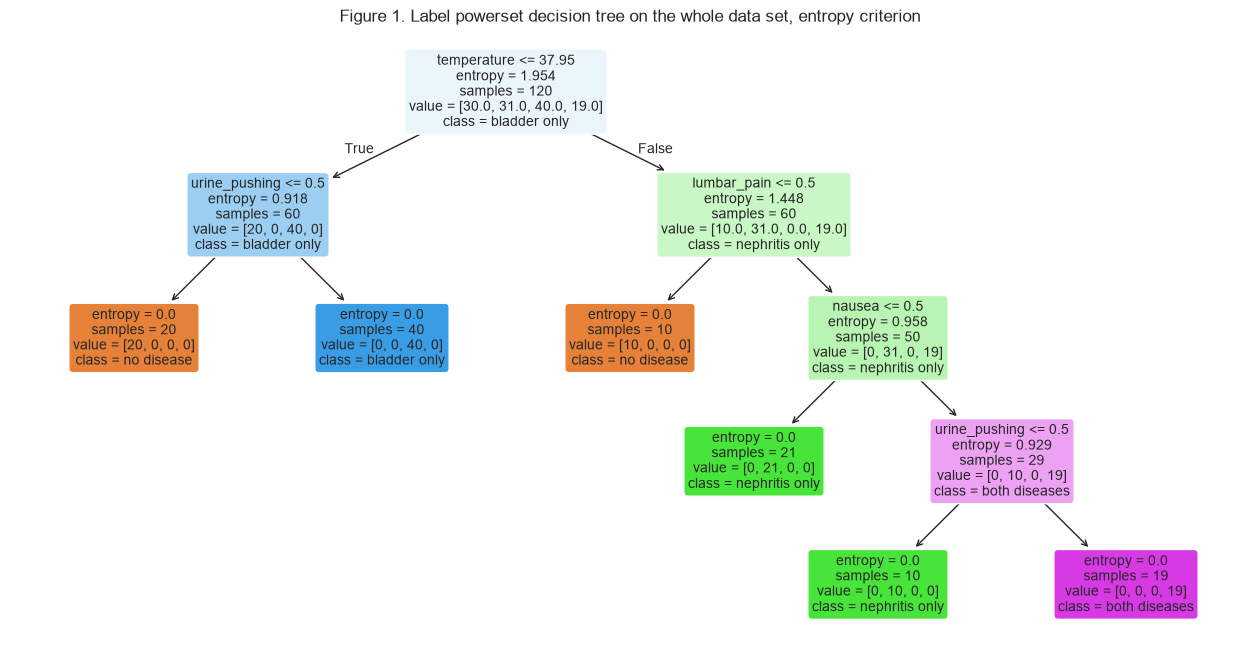

In [5]:
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(tree_full, feature_names=FEATURES, class_names=class_labels,
          filled=True, rounded=True, impurity=True, fontsize=10, ax=ax)
ax.set_title("Figure 1. Label powerset decision tree on the whole data set, entropy criterion")
plt.show()

The tree has 6 leaves and a depth of 4. It classifies all 120 patients correctly, and every leaf is pure.
It uses only 4 of the 6 features: temperature, lumbar pain, urine pushing and nausea.
The 5 symptom features are 0 or 1, so a split such as `lumbar_pain <= 0.5` just means "lumbar pain is no".

### 1c. Converting the tree into IF-THEN rules

The code below follows the idea of the KDnuggets article. It walks through the fitted tree from the root to each leaf.
I print the rules in two forms:

1. Nested IF and ELSE blocks, like the `tree_to_code` function in the article.
2. Flat IF-THEN rules, one rule for each leaf. A rule joins all the conditions on the path from the root to the leaf with AND.

For the 0 or 1 symptom features, I write the conditions as `= yes` or `= no` instead of `<= 0.5` and `> 0.5`.

In [6]:
def describe_split(name, threshold, go_left):
    # Turns a split into readable text. The 0/1 symptoms become "= yes" or "= no".
    if name in SYMPTOMS:
        return f"{name} = {'no' if go_left else 'yes'}"
    return f"{name} {'<=' if go_left else '>'} {threshold:.2f}"


def leaf_class(tree, node, class_labels):
    return class_labels[int(np.argmax(tree.tree_.value[node][0]))]


def tree_to_code(tree, feature_names, class_labels):
    # Nested IF / ELSE form, adapted from the KDnuggets article.
    t = tree.tree_
    lines = []

    def recurse(node, depth):
        indent = "    " * depth
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, thr = feature_names[t.feature[node]], t.threshold[node]
            lines.append(f"{indent}IF {describe_split(name, thr, True)}:")
            recurse(t.children_left[node], depth + 1)
            lines.append(f"{indent}ELSE:  # {describe_split(name, thr, False)}")
            recurse(t.children_right[node], depth + 1)
        else:
            lines.append(f"{indent}RETURN {leaf_class(tree, node, class_labels)}"
                         f"  # {t.n_node_samples[node]} patients")

    recurse(0, 0)
    return "\n".join(lines)


def tree_to_rules(tree, feature_names, class_labels):
    # One rule per leaf: the list of conditions, the predicted class and the number of training samples.
    t = tree.tree_
    rules = []

    def recurse(node, conditions):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, thr = feature_names[t.feature[node]], t.threshold[node]
            recurse(t.children_left[node], conditions + [describe_split(name, thr, True)])
            recurse(t.children_right[node], conditions + [describe_split(name, thr, False)])
        else:
            rules.append((conditions, leaf_class(tree, node, class_labels), t.n_node_samples[node]))

    recurse(0, [])
    return rules


def print_rules(rules):
    for i, (conditions, label, n) in enumerate(rules, start=1):
        print(f"Rule {i}, {n} patients:")
        print(f"    IF {' AND '.join(conditions) if conditions else 'TRUE'}")
        print(f"    THEN {label}")


print(tree_to_code(tree_full, FEATURES, class_labels))

IF temperature <= 37.95:
    IF urine_pushing = no:
        RETURN no disease  # 20 patients
    ELSE:  # urine_pushing = yes
        RETURN bladder only  # 40 patients
ELSE:  # temperature > 37.95
    IF lumbar_pain = no:
        RETURN no disease  # 10 patients
    ELSE:  # lumbar_pain = yes
        IF nausea = no:
            RETURN nephritis only  # 21 patients
        ELSE:  # nausea = yes
            IF urine_pushing = no:
                RETURN nephritis only  # 10 patients
            ELSE:  # urine_pushing = yes
                RETURN both diseases  # 19 patients


In [7]:
rules_full = tree_to_rules(tree_full, FEATURES, class_labels)
print_rules(rules_full)

Rule 1, 20 patients:
    IF temperature <= 37.95 AND urine_pushing = no
    THEN no disease
Rule 2, 40 patients:
    IF temperature <= 37.95 AND urine_pushing = yes
    THEN bladder only
Rule 3, 10 patients:
    IF temperature > 37.95 AND lumbar_pain = no
    THEN no disease
Rule 4, 21 patients:
    IF temperature > 37.95 AND lumbar_pain = yes AND nausea = no
    THEN nephritis only
Rule 5, 10 patients:
    IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = no
    THEN nephritis only
Rule 6, 19 patients:
    IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = yes
    THEN both diseases


The 6 rules cover all 120 patients, and no two rules overlap. In plain words:

* If the temperature is 37.95 °C or lower, the patient never has nephritis. Urine pushing then decides bladder inflammation.
  These are rules 1 and 2.
* If the temperature is above 37.95 °C and there is no lumbar pain, the patient has neither disease. This is rule 3.
* If the temperature is above 37.95 °C and there is lumbar pain, the patient has nephritis.
  The patient also has bladder inflammation only when both nausea and urine pushing are present. These are rules 4, 5 and 6.

### 1d. Cost-complexity pruning

Cost-complexity pruning picks the subtree that makes this cost as small as possible:

$$\text{cost} = \text{total leaf impurity} + \alpha \times \text{number of leaves}$$

In the total leaf impurity, each leaf is weighted by its share of the samples.
A larger $\alpha$ gives a smaller tree. The function `cost_complexity_pruning_path` returns the values of $\alpha$ where the best subtree changes.

I choose $\alpha$ by cross-validation. For each $\alpha$ on the path, I compute the accuracy with 5-fold stratified cross-validation, repeated 10 times.
The minimal tree is the tree with the largest $\alpha$ whose CV accuracy is equal to the best CV accuracy. The largest $\alpha$ gives the fewest leaves.

In [8]:
path = tree_full.cost_complexity_pruning_path(X_diag, y_powerset)
cv_diag = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

rows = []
for alpha, impurity in zip(path.ccp_alphas, path.impurities):
    model = DecisionTreeClassifier(criterion="entropy", ccp_alpha=alpha, random_state=RANDOM_STATE)
    cv_res = cross_validate(model, X_diag, y_powerset, cv=cv_diag, return_estimator=True)
    model.fit(X_diag, y_powerset)
    rows.append({"ccp_alpha": alpha, "total leaf impurity": impurity,
                 "leaves": model.get_n_leaves(), "depth": model.get_depth(),
                 "training accuracy": model.score(X_diag, y_powerset),
                 "mean CV accuracy": cv_res["test_score"].mean(),
                 "std of CV accuracy": cv_res["test_score"].std(),
                 "mean leaves in CV folds": np.mean([est.get_n_leaves() for est in cv_res["estimator"]])})
pruning = pd.DataFrame(rows)
display(pruning.round(4))

,ccp_alpha,total leaf impurity,leaves,depth,training accuracy,mean CV accuracy,std of CV accuracy,mean leaves in CV folds
0,0.0000,0.0000,6,4,1.0000,1.0000,0.0000,6.0
1,0.1996,0.3992,4,2,0.8417,0.8600,0.0611,4.4
2,0.3250,0.7242,3,2,0.7583,0.7658,0.0571,3.3
3,0.4591,1.1833,2,1,0.5917,0.6242,0.0556,2.3
4,0.7704,1.9538,1,0,0.3333,0.5150,0.1198,1.7


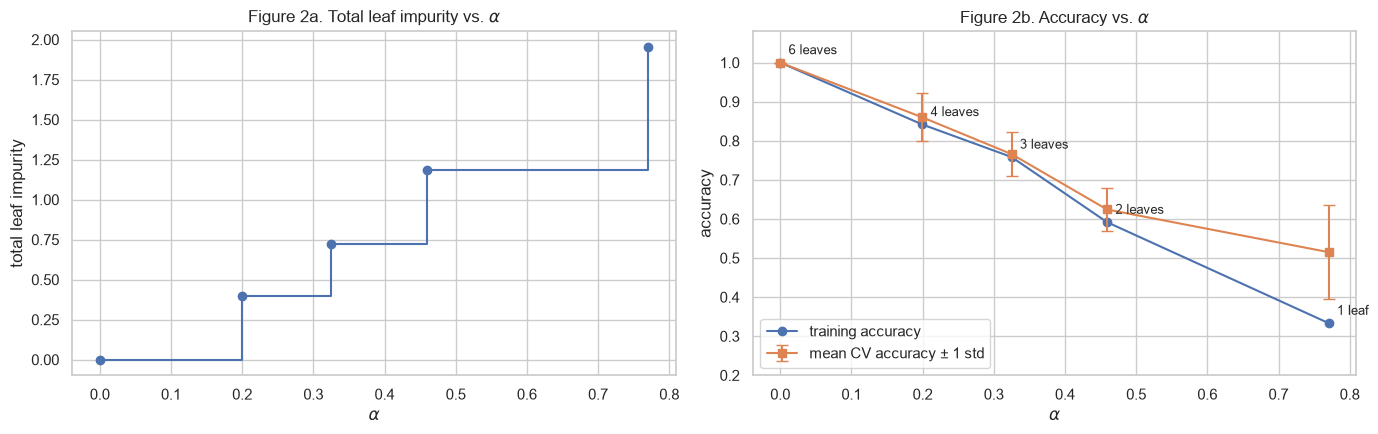

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(pruning["ccp_alpha"], pruning["total leaf impurity"], marker="o", drawstyle="steps-post")
axes[0].set(xlabel=r"$\alpha$", ylabel="total leaf impurity",
            title="Figure 2a. Total leaf impurity vs. $\\alpha$")

axes[1].plot(pruning["ccp_alpha"], pruning["training accuracy"], marker="o", label="training accuracy")
axes[1].errorbar(pruning["ccp_alpha"], pruning["mean CV accuracy"], yerr=pruning["std of CV accuracy"],
                 marker="s", capsize=4, label="mean CV accuracy ± 1 std")
for _, r in pruning.iterrows():
    n_leaves = int(r["leaves"])
    axes[1].annotate(f"{n_leaves} leaf" if n_leaves == 1 else f"{n_leaves} leaves",
                     (r["ccp_alpha"], r["training accuracy"]),
                     textcoords="offset points", xytext=(6, 6), fontsize=9)
axes[1].set(xlabel=r"$\alpha$", ylabel="accuracy", ylim=(0.2, 1.08),
            title="Figure 2b. Accuracy vs. $\\alpha$")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

In [10]:
best_cv = pruning["mean CV accuracy"].max()
chosen = pruning[pruning["mean CV accuracy"] >= best_cv - 1e-12].iloc[-1]
alpha_best = chosen["ccp_alpha"]
print(f"best mean CV accuracy = {best_cv:.4f}")
print(f"chosen ccp_alpha = {alpha_best:.4f}, which gives {int(chosen['leaves'])} leaves and depth {int(chosen['depth'])}")

tree_pruned = DecisionTreeClassifier(criterion="entropy", ccp_alpha=alpha_best, random_state=RANDOM_STATE)
tree_pruned.fit(X_diag, y_powerset)
print(f"training accuracy of the pruned tree = {tree_pruned.score(X_diag, y_powerset):.3f}")
print("same tree as in 1b:", export_text(tree_pruned, feature_names=FEATURES)
      == export_text(tree_full, feature_names=FEATURES))

best mean CV accuracy = 1.0000
chosen ccp_alpha = 0.0000, which gives 6 leaves and depth 4
training accuracy of the pruned tree = 1.000
same tree as in 1b: True


Cross-validation picks $\alpha = 0$. So the minimal tree with the best accuracy is the tree from 1b. It has 6 leaves and makes no errors.

The pruning path shows why. The tree from 1b is already small, and every split is needed to keep the leaves pure. So any pruning causes errors:

* The next step on the path, at $\alpha \approx 0.20$, removes the nausea split and the urine pushing split below it.
  The tree then has 4 leaves. The training accuracy drops to about 84%, and the CV accuracy drops to 86%.
* Larger values of $\alpha$ make the tree even worse. The 1-leaf tree always predicts the largest class, bladder only,
  and its training accuracy is 33%.

For every pruned tree, the CV accuracy is higher than the training accuracy. This is not a mistake.
The values of $\alpha$ come from the full data set, and on a training fold the same $\alpha$ often keeps a bigger tree.
The column "mean leaves in CV folds" shows this. For example, at $\alpha \approx 0.20$ the tree on the full data has 4 leaves,
but the trees in the CV folds have 4.4 leaves on average.

The tree fits the data with no errors, and its CV accuracy is also 100%. So the labels have no noise for pruning to remove.
This makes sense, because a medical expert made this data set to test an expert system.

For comparison, the 4-leaf tree at the next $\alpha$ is shown below. It is a little easier to read, but it is wrong for 19 of the 120 patients.

In [11]:
alpha_next = pruning["ccp_alpha"].iloc[1]
tree_4 = DecisionTreeClassifier(criterion="entropy", ccp_alpha=alpha_next, random_state=RANDOM_STATE)
tree_4.fit(X_diag, y_powerset)
print(f"ccp_alpha = {alpha_next:.4f}: {tree_4.get_n_leaves()} leaves, "
      f"training accuracy = {tree_4.score(X_diag, y_powerset):.3f}, "
      f"errors = {(tree_4.predict(X_diag) != y_powerset).sum()} of {len(y_powerset)}\n")
print_rules(tree_to_rules(tree_4, FEATURES, [CLASS_NAMES[c] for c in tree_4.classes_]))

ccp_alpha = 0.1996: 4 leaves, training accuracy = 0.842, errors = 19 of 120

Rule 1, 20 patients:
    IF temperature <= 37.95 AND urine_pushing = no
    THEN no disease
Rule 2, 40 patients:
    IF temperature <= 37.95 AND urine_pushing = yes
    THEN bladder only
Rule 3, 10 patients:
    IF temperature > 37.95 AND lumbar_pain = no
    THEN no disease
Rule 4, 50 patients:
    IF temperature > 37.95 AND lumbar_pain = yes
    THEN nephritis only


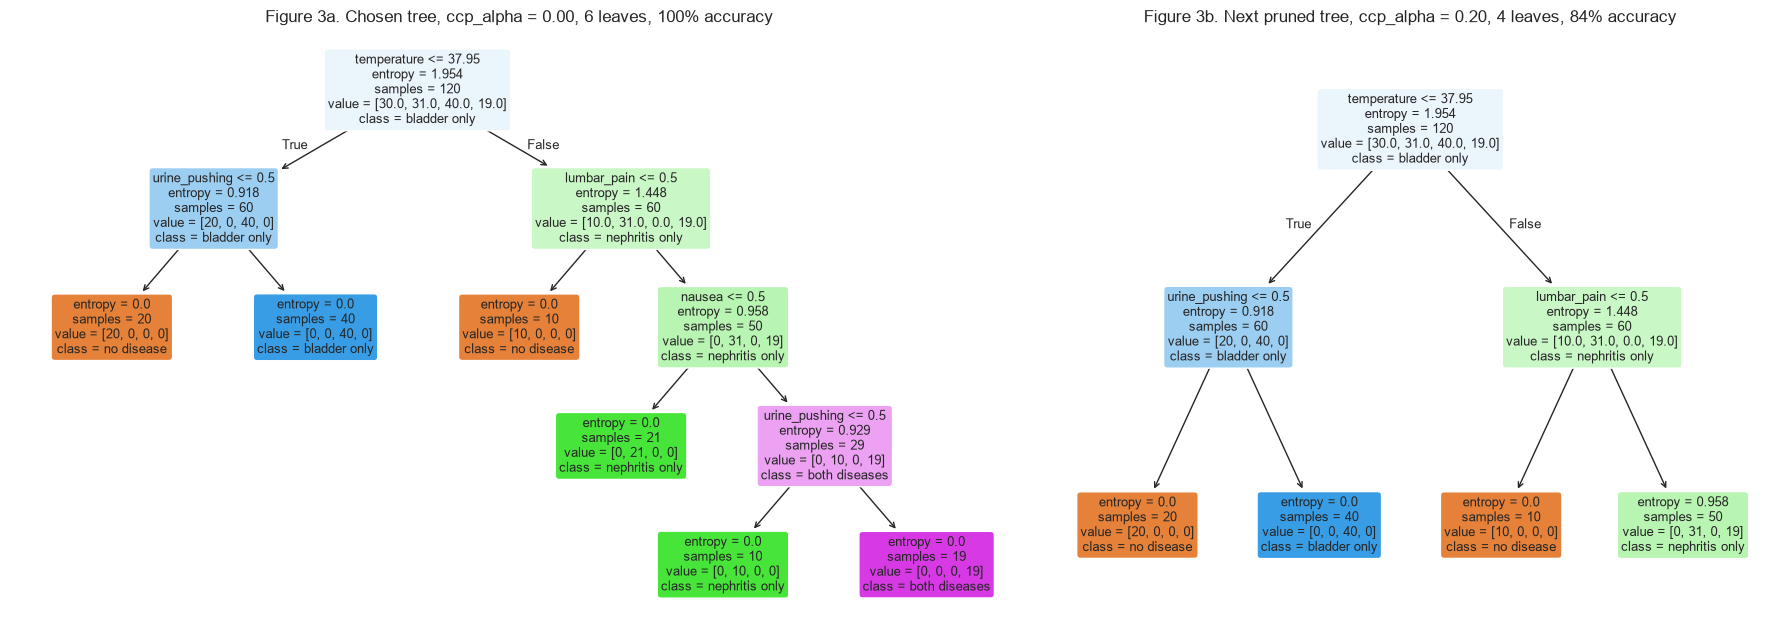

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.4, 1]})
plot_tree(tree_pruned, feature_names=FEATURES, class_names=class_labels,
          filled=True, rounded=True, fontsize=9, ax=axes[0])
axes[0].set_title(f"Figure 3a. Chosen tree, ccp_alpha = {alpha_best:.2f}, 6 leaves, 100% accuracy")
plot_tree(tree_4, feature_names=FEATURES, class_names=[CLASS_NAMES[c] for c in tree_4.classes_],
          filled=True, rounded=True, fontsize=9, ax=axes[1])
axes[1].set_title(f"Figure 3b. Next pruned tree, ccp_alpha = {alpha_next:.2f}, 4 leaves, 84% accuracy")
plt.tight_layout()
plt.show()

#### Final decision rules

Rules with the same result can be merged. Writing one rule for each disease gives two short rules that are easy to read:

* Nephritis of renal pelvis origin is yes if the temperature is above 37.95 °C and the patient has lumbar pain.
  This rule merges rules 4, 5 and 6.
* Inflammation of urinary bladder is yes if the patient has urine pushing and one of these is true:
  the temperature is 37.95 °C or lower, or the patient has both lumbar pain and nausea. This rule merges rules 2 and 6.

The cell below checks that these two rules give the correct labels for all 120 patients.

In [13]:
hot = diag["temperature"] > 37.95
pred_nephritis = (hot & (diag["lumbar_pain"] == 1)).astype(int)
pred_bladder = ((diag["urine_pushing"] == 1)
                & (~hot | ((diag["lumbar_pain"] == 1) & (diag["nausea"] == 1)))).astype(int)

print("nephritis rule is correct for", (pred_nephritis == diag["nephritis"]).sum(), "of", len(diag), "patients")
print("bladder rule is correct for  ", (pred_bladder == diag["bladder_inflammation"]).sum(), "of", len(diag), "patients")

nephritis rule is correct for 120 of 120 patients
bladder rule is correct for   120 of 120 patients


#### Comparison with binary relevance and the multi-output tree

To check my answer to the footnote, I also build the binary relevance trees, one for each label,
and one scikit-learn multi-output tree.

Binary relevance tree for bladder_inflammation:
Rule 1, 40 patients:
    IF urine_pushing = no
    THEN bladder_inflammation = no
Rule 2, 10 patients:
    IF urine_pushing = yes AND micturition_pains = no AND burning_urethra = no
    THEN bladder_inflammation = yes
Rule 3, 21 patients:
    IF urine_pushing = yes AND micturition_pains = no AND burning_urethra = yes
    THEN bladder_inflammation = no
Rule 4, 49 patients:
    IF urine_pushing = yes AND micturition_pains = yes
    THEN bladder_inflammation = yes

Binary relevance tree for nephritis:
Rule 1, 60 patients:
    IF temperature <= 37.95
    THEN nephritis = no
Rule 2, 10 patients:
    IF temperature > 37.95 AND lumbar_pain = no
    THEN nephritis = no
Rule 3, 50 patients:
    IF temperature > 37.95 AND lumbar_pain = yes
    THEN nephritis = yes



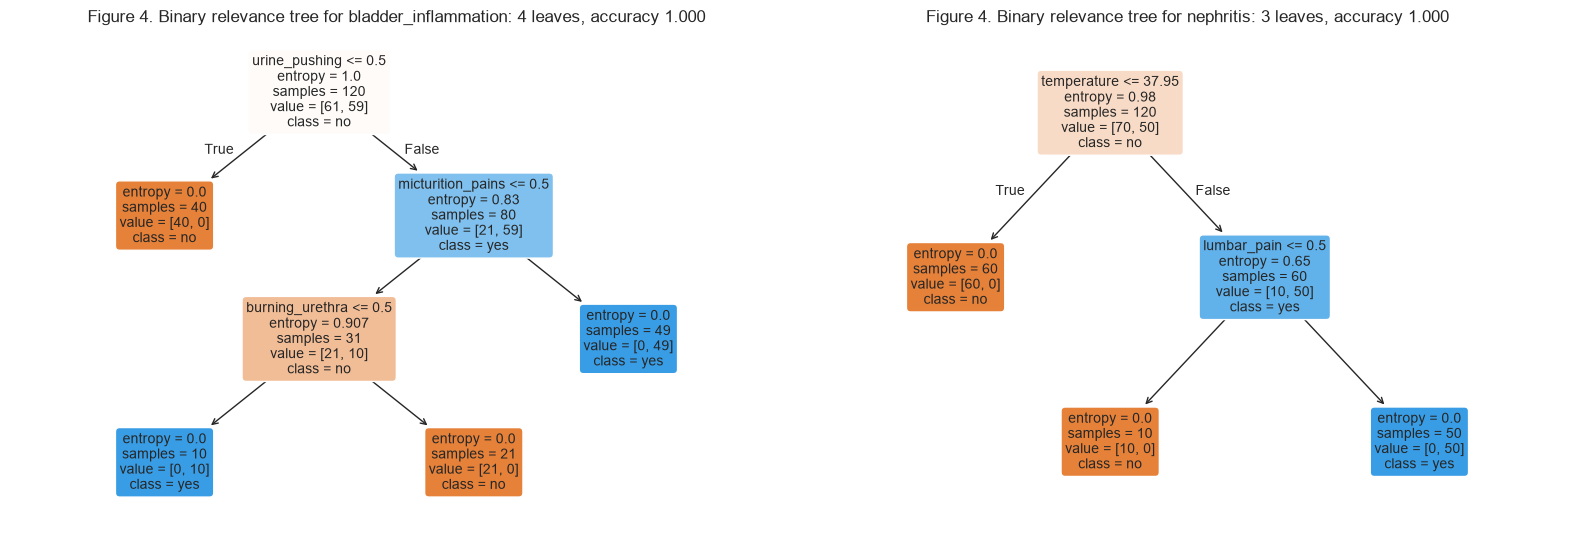

multi-output tree: 6 leaves, same splits as the label powerset tree: True


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, label in zip(axes, LABELS):
    br_tree = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE).fit(X_diag, Y_diag[label])
    plot_tree(br_tree, feature_names=FEATURES, class_names=["no", "yes"],
              filled=True, rounded=True, fontsize=10, ax=ax)
    ax.set_title(f"Figure 4. Binary relevance tree for {label}: "
                 f"{br_tree.get_n_leaves()} leaves, accuracy {br_tree.score(X_diag, Y_diag[label]):.3f}")
    print(f"Binary relevance tree for {label}:")
    print_rules(tree_to_rules(br_tree, FEATURES, [f"{label} = no", f"{label} = yes"]))
    print()
plt.tight_layout()
plt.show()

multi = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE).fit(X_diag, Y_diag)
same_splits = (np.array_equal(multi.tree_.feature, tree_full.tree_.feature)
               and np.allclose(multi.tree_.threshold, tree_full.tree_.threshold))
print(f"multi-output tree: {multi.get_n_leaves()} leaves, "
      f"same splits as the label powerset tree: {same_splits}")

All three methods fit the data with no errors. The multi-output tree has exactly the same splits as the label powerset tree.
Binary relevance needs two trees with 7 leaves in total. The label powerset tree is one tree with 6 leaves.

## 2. The LASSO and Boosting for Regression

### 2a. Loading the Communities and Crime data

The data file has no header. I take the 128 column names from the `@attribute` lines in `communities.names`.
A `?` marks a missing value. As the assignment says, the first 1495 rows are the training set and the other 499 rows are the test set.

In [15]:
column_names = [line.split()[1] for line in open(DATA_DIR / "communities.names")
                if line.startswith("@attribute")]
crime = pd.read_csv(DATA_DIR / "communities.data", header=None, names=column_names, na_values="?")
TARGET = "ViolentCrimesPerPop"
print(f"{crime.shape[0]} rows and {crime.shape[1]} columns")
print("first columns:", ", ".join(column_names[:6]))
print("target:", column_names[-1])

1994 rows and 128 columns
first columns: state, county, community, communityname, fold, population
target: ViolentCrimesPerPop


### 2b. Dropping the non-predictive features and filling in missing values

`communities.names` says that the first 5 attributes are not predictive: `state`, `county`, `community`, `communityname` and `fold`.
They are IDs or the number of a cross-validation fold, so I drop them. This leaves 122 predictive features and the target.

In [16]:
NON_PREDICTIVE = ["state", "county", "community", "communityname", "fold"]
crime = crime.drop(columns=NON_PREDICTIVE)

train, test = crime.iloc[:1495], crime.iloc[1495:]
X_train_raw, y_train = train.drop(columns=TARGET), train[TARGET]
X_test_raw, y_test = test.drop(columns=TARGET), test[TARGET]
FEATURE_NAMES = X_train_raw.columns.tolist()
print(f"training set: {len(X_train_raw)} rows, test set: {len(X_test_raw)} rows, features: {len(FEATURE_NAMES)}")

missing = crime.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"\n{len(missing)} features have missing values. The target has {crime[TARGET].isna().sum()} missing values.")
display(pd.DataFrame({"missing in all rows": missing,
                      "missing in training rows": X_train_raw[missing.index].isna().sum(),
                      "share missing": (missing / len(crime)).round(3)}))

lemas_missing = missing.index[missing == missing.max()]
print(f"rows where all {len(lemas_missing)} LEMAS features are missing: "
      f"{int(crime[lemas_missing].isna().all(axis=1).sum())}, "
      f"rows where at least one is missing: {int(crime[lemas_missing].isna().any(axis=1).sum())}")

training set: 1495 rows, test set: 499 rows, features: 122

23 features have missing values. The target has 0 missing values.


,missing in all rows,missing in training rows,share missing
LemasSwornFT,1675,1256,0.840
LemasSwFTPerPop,1675,1256,0.840
LemasSwFTFieldOps,1675,1256,0.840
LemasTotalReq,1675,1256,0.840
LemasSwFTFieldPerPop,1675,1256,0.840
LemasTotReqPerPop,1675,1256,0.840
PolicReqPerOffic,1675,1256,0.840
OfficAssgnDrugUnits,1675,1256,0.840
PolicPerPop,1675,1256,0.840
RacialMatchCommPol,1675,1256,0.840


rows where all 22 LEMAS features are missing: 1675, rows where at least one is missing: 1675


Only 23 features have missing values, and the target has none.

* `OtherPerCap` is missing for 1 community.
* 22 police features from the LEMAS survey are missing for 1675 of the 1994 communities, which is 84%.
  The data description says that the LEMAS survey mainly covered police departments with at least 100 officers,
  so many communities have no LEMAS data. The last line above shows that these 22 features are missing for exactly the same communities.

I fill in each missing value with the median of that feature. All values in this data set are scaled to the range 0 to 1,
and many features are skewed, so the median is a safer choice than the mean.
The imputer learns the medians from the training set only. Then it fills in both the training set and the test set.
So the test set has no effect on the models.

After imputation, 84% of the values of each LEMAS feature are the same number, so these features carry little information.
I still keep them, because the assignment asks me to fill in the missing values, not to drop features.

In [17]:
imputer = SimpleImputer(strategy="median").fit(X_train_raw)
X_train = pd.DataFrame(imputer.transform(X_train_raw), columns=FEATURE_NAMES, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=FEATURE_NAMES, index=X_test_raw.index)

# Full imputed data. Parts 2c to 2e use it to describe the data.
X_all = pd.concat([X_train, X_test])
crime_imputed = X_all.assign(**{TARGET: crime[TARGET]})
print("missing values left:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))

missing values left: 0


### 2c. Correlation matrix

The heat map shows the Pearson correlation matrix of the 122 features and the target. I use the full imputed data set with all 1994 rows.
Parts 2c, 2d and 2e only describe the data. They do not change any model.

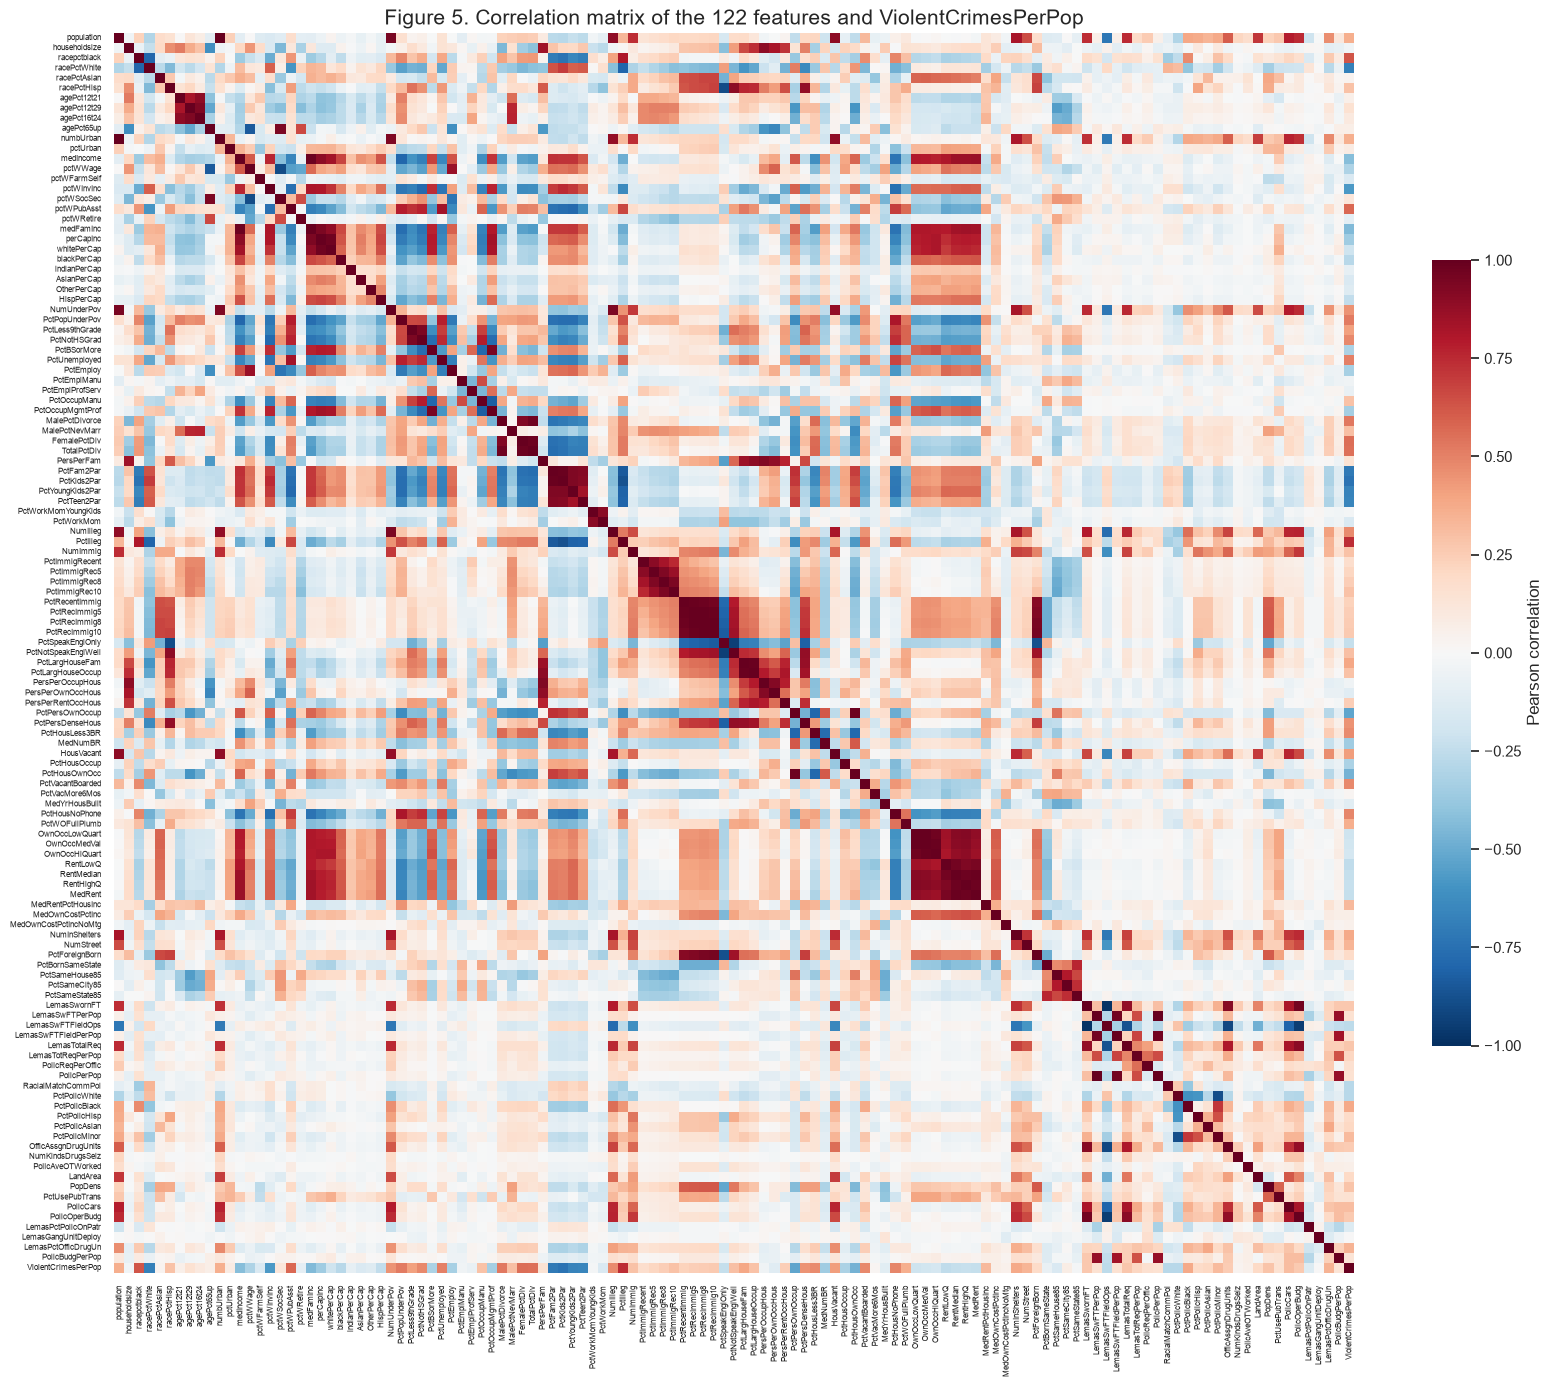

In [18]:
corr = crime_imputed.corr()
fig, ax = plt.subplots(figsize=(20, 17))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6, "label": "Pearson correlation"}, ax=ax)
ax.tick_params(labelsize=5.5)
ax.set_title("Figure 5. Correlation matrix of the 122 features and ViolentCrimesPerPop", fontsize=15)
plt.show()

feature pairs with an absolute correlation above 0.9: 58


,,correlation
LemasSwFTPerPop,PolicPerPop,0.999994
PctRecImmig8,PctRecImmig10,0.995525
OwnOccLowQuart,OwnOccMedVal,0.994481
PctRecImmig5,PctRecImmig8,0.993433
population,numbUrban,0.993112
LemasSwornFT,LemasSwFTFieldOps,-0.991590
OwnOccMedVal,OwnOccHiQuart,0.991302
PctRecentImmig,PctRecImmig5,0.988999
RentMedian,MedRent,0.988585
PctRecImmig5,PctRecImmig10,0.985616


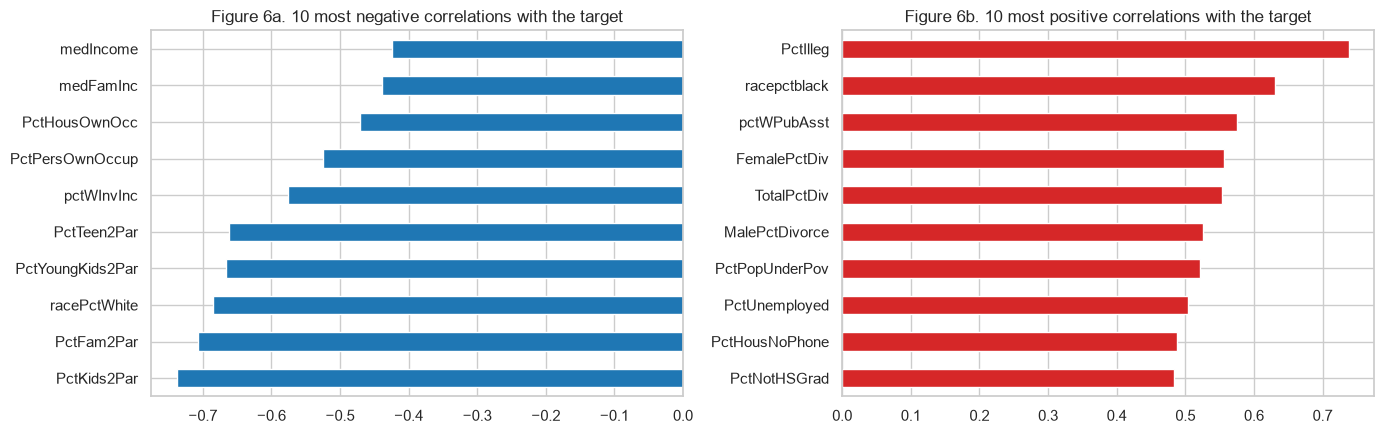

In [19]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("feature pairs with an absolute correlation above 0.9:", int((upper.abs() > 0.9).sum()))
display(upper.reindex(upper.abs().sort_values(ascending=False).index).head(10).rename("correlation").to_frame())

target_corr = corr[TARGET].drop(TARGET).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
target_corr.head(10).plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Figure 6a. 10 most negative correlations with the target")
target_corr.tail(10).plot.barh(ax=axes[1], color="tab:red")
axes[1].set_title("Figure 6b. 10 most positive correlations with the target")
plt.tight_layout()
plt.show()

The matrix has large blocks of strong correlation, and 58 pairs of features have an absolute correlation above 0.9.
Many features measure almost the same thing. Examples are the count features such as `population`, `numbUrban` and `NumUnderPov`,
the income features, and the 22 LEMAS features. So the features are highly collinear.
This can make least squares unstable, and it is a reason to try ridge, the LASSO and PCR.

The target has its strongest positive correlation with `PctIlleg`, the percent of kids born to parents who never married, at r = 0.74.
Other strong positive ones are `racepctblack`, `pctWPubAsst`, which is the percent of households with public assistance income,
and the divorce features. The strongest negative correlation is with `PctKids2Par`, the percent of kids in two-parent families, at r = -0.74.
Other strong negative ones are `PctFam2Par` and `racePctWhite`.

Filling in 84% of a feature with one value usually makes its correlations with other features weaker.
So the correlations of the LEMAS features should be read with care.

### 2d. Coefficient of variation

The coefficient of variation is $CV = s / m$. Here $s$ is the sample standard deviation and $m$ is the sample mean of a feature.
I compute it for all 122 features on the full imputed data set. No feature has a mean of 0, so CV is defined for every feature.

In [20]:
cv_table = pd.DataFrame({"mean": X_all.mean(), "std": X_all.std(ddof=1)})
cv_table["CV"] = cv_table["std"] / cv_table["mean"]
cv_table = cv_table.sort_values("CV", ascending=False)
print(f"features with a mean of 0: {int((cv_table['mean'] == 0).sum())}")
print(f"CV goes from {cv_table['CV'].min():.3f} to {cv_table['CV'].max():.3f}")

with pd.option_context("display.max_rows", 130):
    display(cv_table.round(4))

features with a mean of 0: 0
CV goes from 0.058 to 5.448


,mean,std,CV
PctPolicAsian,0.0184,0.1001,5.4478
NumStreet,0.0228,0.1004,4.4077
NumInShelters,0.0294,0.1026,3.4855
NumIlleg,0.0363,0.1087,2.9942
NumImmig,0.0301,0.0872,2.9005
LemasPctOfficDrugUn,0.0941,0.2403,2.5553
NumUnderPov,0.0555,0.1279,2.3050
population,0.0576,0.1269,2.2035
LemasSwornFT,0.0279,0.0581,2.0807
numbUrban,0.0641,0.1283,2.0017


### 2e. Features with the highest CV

$\lfloor\sqrt{128}\rfloor = \lfloor 11.31 \rfloor = 11$, so I take the 11 features with the highest CV.

In [21]:
n_top = int(np.floor(np.sqrt(128)))
top_cv = cv_table.index[:n_top].tolist()
print(f"floor of sqrt 128 = {n_top}")
display(cv_table.loc[top_cv].round(4))

floor of sqrt 128 = 11


,mean,std,CV
PctPolicAsian,0.0184,0.1001,5.4478
NumStreet,0.0228,0.1004,4.4077
NumInShelters,0.0294,0.1026,3.4855
NumIlleg,0.0363,0.1087,2.9942
NumImmig,0.0301,0.0872,2.9005
LemasPctOfficDrugUn,0.0941,0.2403,2.5553
NumUnderPov,0.0555,0.1279,2.3050
population,0.0576,0.1269,2.2035
LemasSwornFT,0.0279,0.0581,2.0807
numbUrban,0.0641,0.1283,2.0017


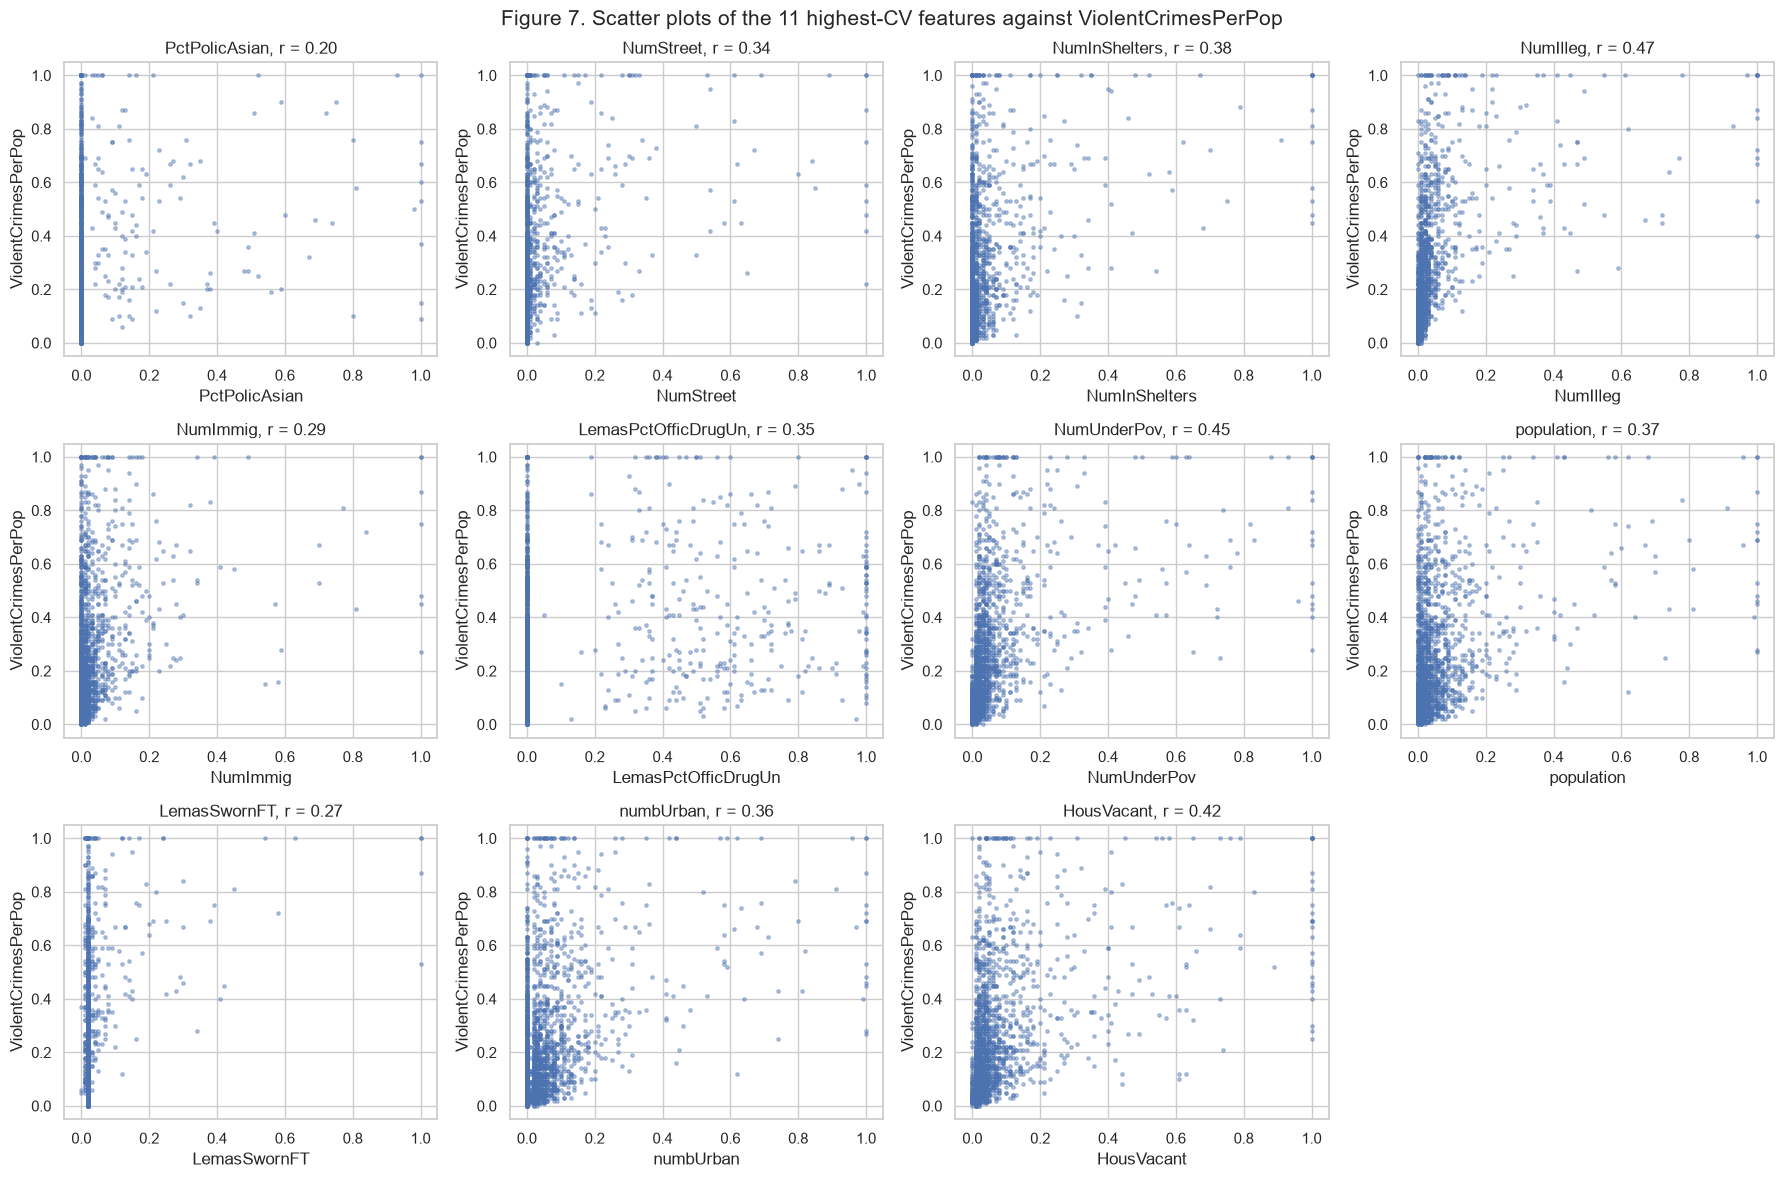

In [22]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, feat in zip(axes.flat, top_cv):
    ax.scatter(crime_imputed[feat], crime_imputed[TARGET], s=6, alpha=0.4)
    ax.set(xlabel=feat, ylabel=TARGET,
           title=f"{feat}, r = {crime_imputed[feat].corr(crime_imputed[TARGET]):.2f}")
axes.flat[-1].axis("off")
fig.suptitle("Figure 7. Scatter plots of the 11 highest-CV features against ViolentCrimesPerPop", fontsize=15)
plt.tight_layout()
plt.show()

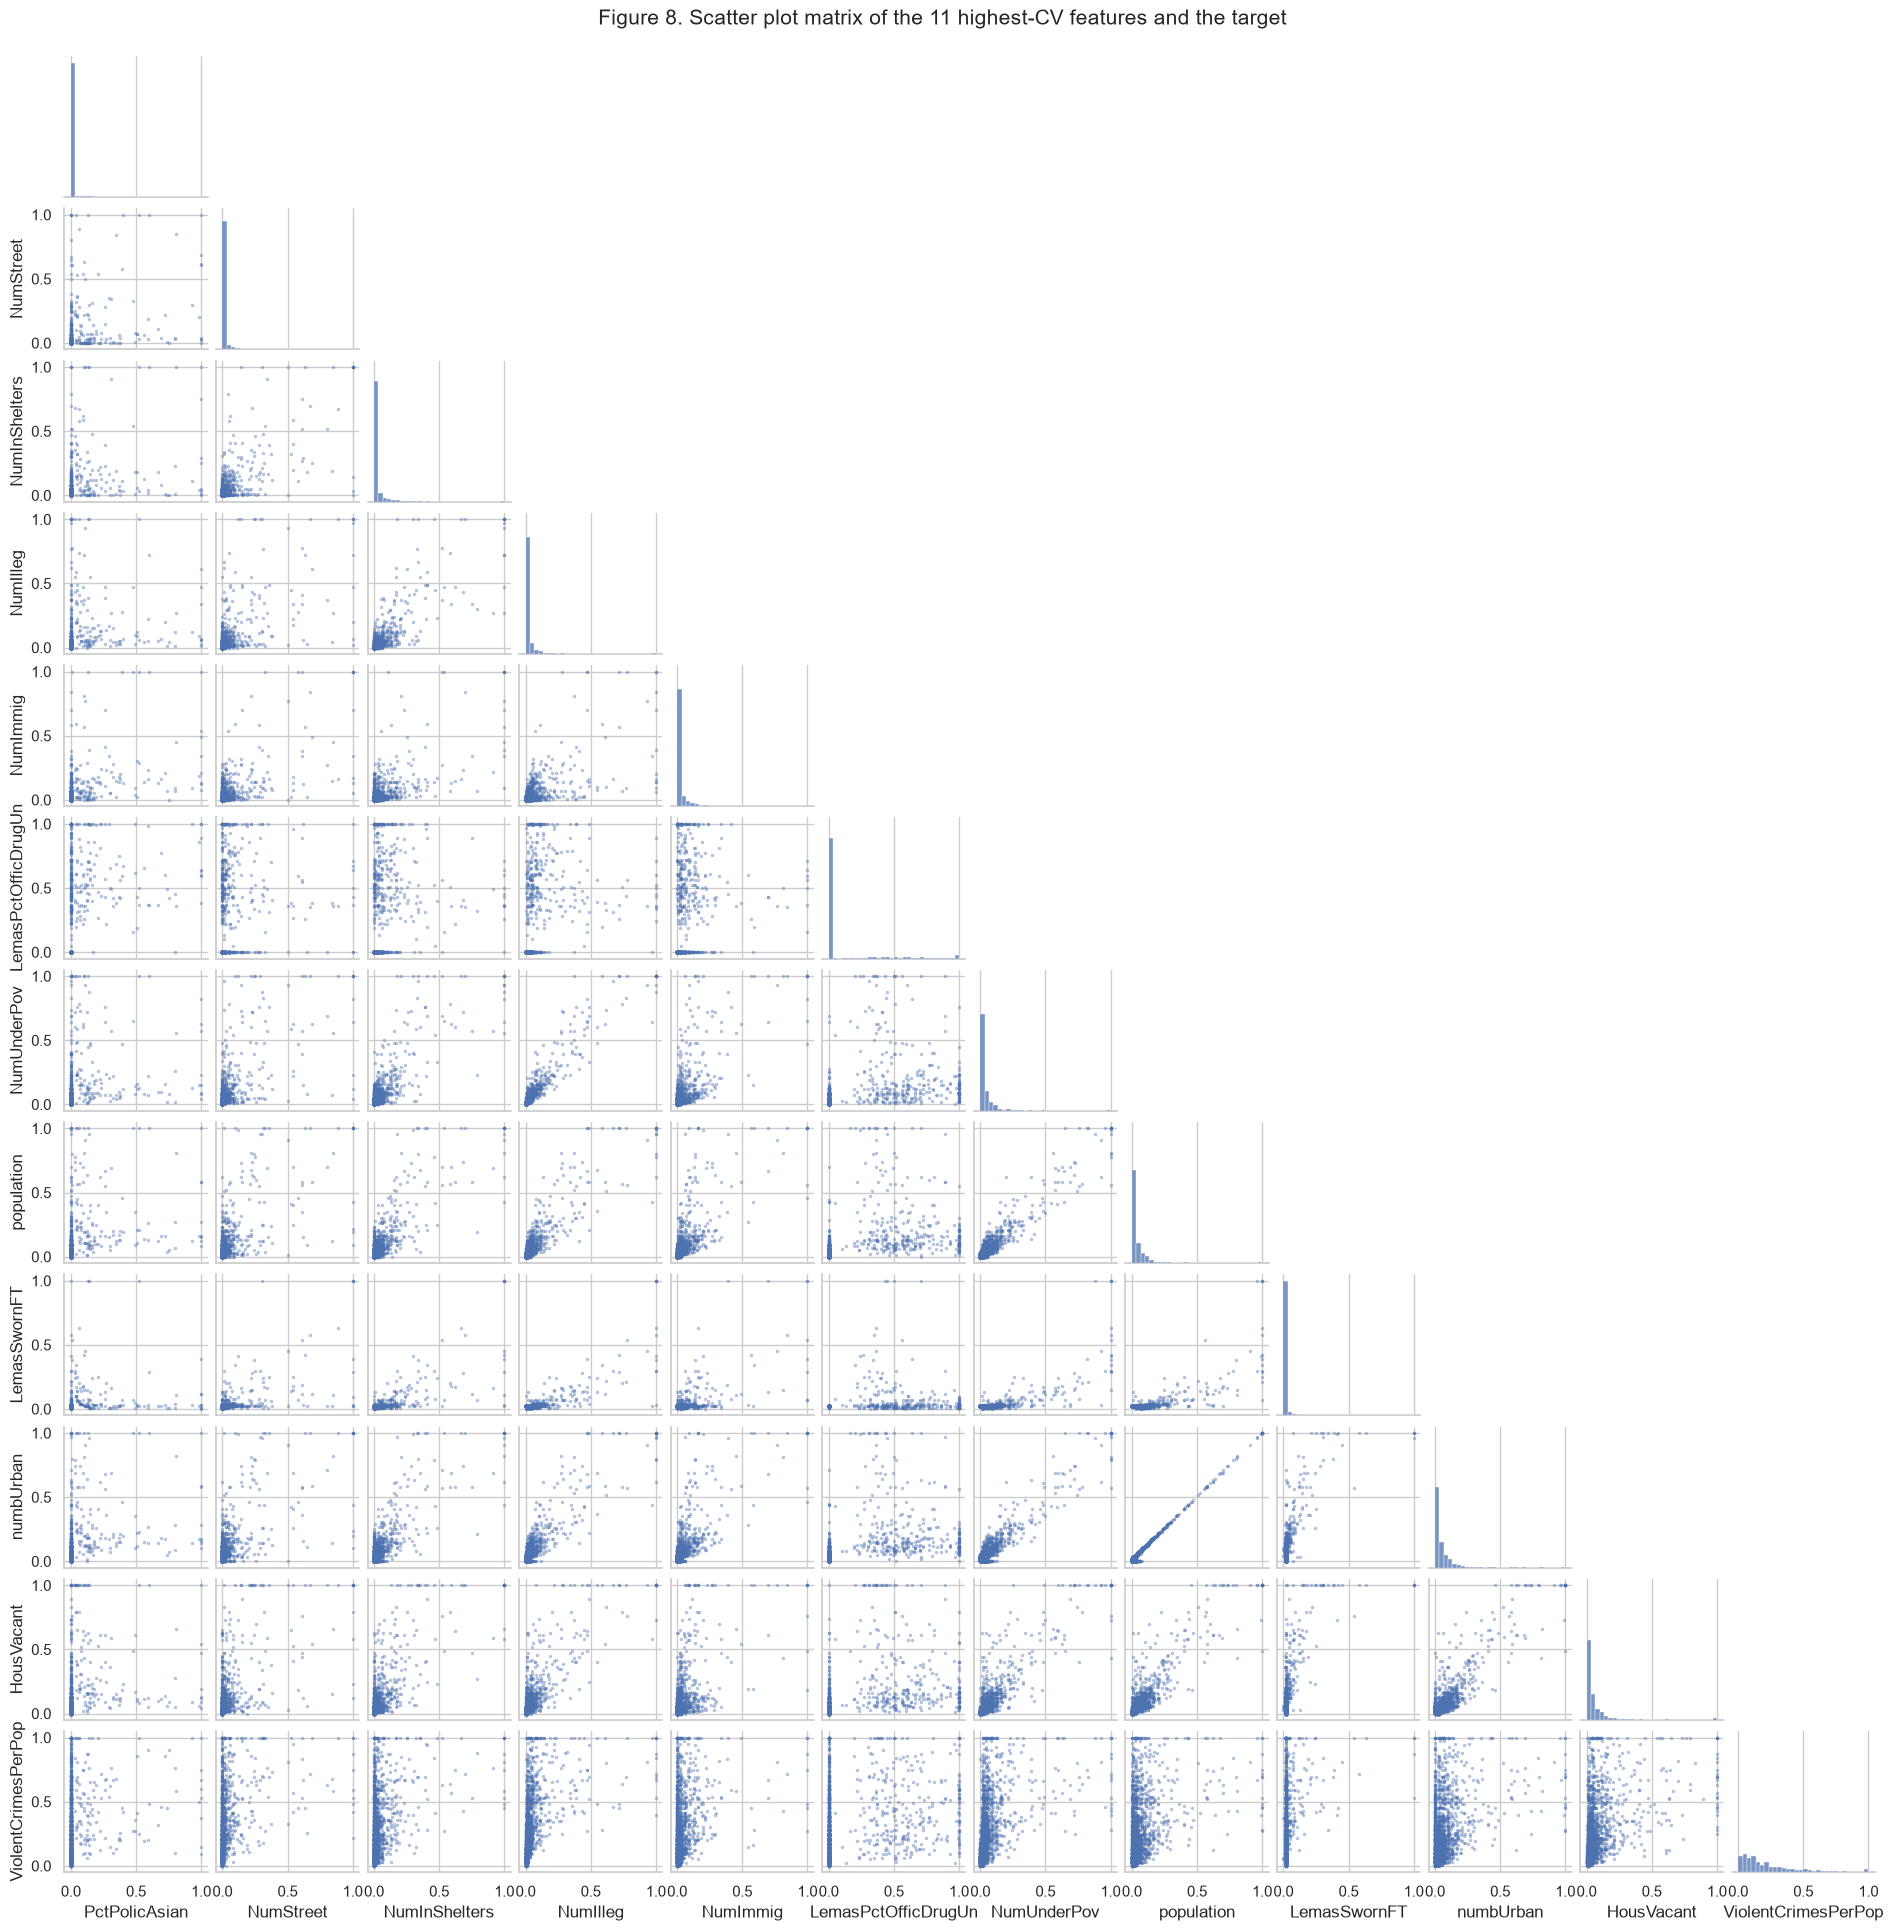

In [23]:
grid = sns.pairplot(crime_imputed[top_cv + [TARGET]], corner=True, height=1.6,
                    plot_kws={"s": 5, "alpha": 0.4, "edgecolor": None}, diag_kws={"bins": 30})
grid.figure.suptitle("Figure 8. Scatter plot matrix of the 11 highest-CV features and the target", fontsize=15, y=1.01)
plt.show()

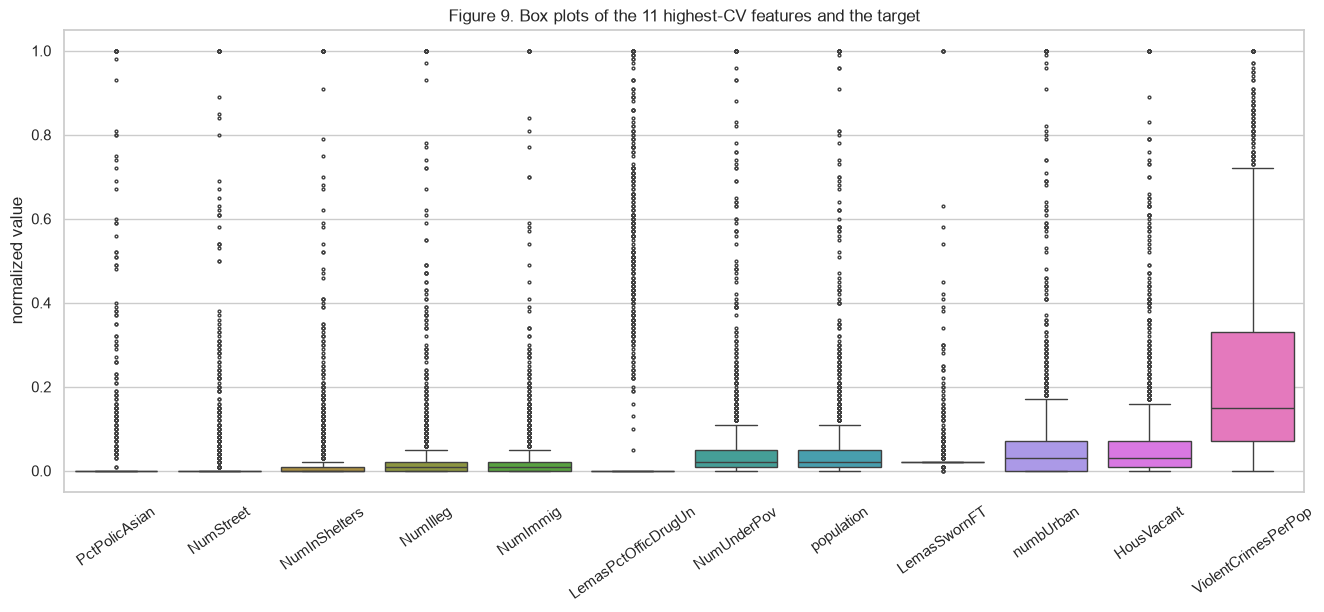

share of zeros in LemasPctOfficDrugUn: 0.845


In [24]:
fig, ax = plt.subplots(figsize=(16, 6))
sns.boxplot(data=crime_imputed[top_cv + [TARGET]], orient="v", fliersize=2, ax=ax)
ax.set(ylabel="normalized value",
       title="Figure 9. Box plots of the 11 highest-CV features and the target")
ax.tick_params(axis="x", rotation=35)
plt.show()

print("share of zeros in LemasPctOfficDrugUn:", round(float((crime_imputed["LemasPctOfficDrugUn"] == 0).mean()), 3))

Can the scatter plots alone show if these features are significant? No, not in a reliable way. The reasons are:

* The plots show some weak positive trends. For example, communities with a large `NumIlleg`, `NumUnderPov` or `HousVacant`
  tend to have more violent crime. Their correlations with the target are 0.47, 0.45 and 0.42.
  But most points sit near 0, and the target varies a lot for every value of the feature.
  By eye, it is hard to tell a real trend from the effect of a few outliers.
* A scatter plot of one feature against the target only shows how the two are related on their own.
  In a regression model, a feature is significant if it still helps when all the other features are in the model.
  The features are highly correlated, as 2c showed. For example, `population`, `numbUrban`, `NumUnderPov`, `NumIlleg` and `NumImmig`
  all mostly measure the size of a city. So a feature can look related to the target on its own and still add nothing
  once the others are in the model. The opposite can also happen.
* Significance needs a test, such as a t-test or an F-test with a p-value, or a stable choice by a method such as the LASSO.
  A plot cannot give this.
* A high CV does not mean that a feature is important. CV only measures the spread of a feature compared with its mean.
  Most of the 11 features are counts, such as `NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig` and `population`.
  Most communities are small, so these values are near 0, with a few large cities far away from the rest.
  This makes the mean small and the CV large. The box plots show this: the boxes sit near 0 and there are many outliers.
* For some features, the high CV also comes from the data processing. `PctPolicAsian` and `LemasSwornFT` are LEMAS features,
  and 84% of their values were filled in with the median. In the scatter plots, they look like a vertical line of filled-in points
  plus a small cloud of real values. `LemasPctOfficDrugUn` has no missing values, but it is 0 for about 85% of the communities.
* The data description says that values more than 3 standard deviations above the mean were set to 1.
  This is why many points sit on the line at 1 in the plots.

So the scatter plots are useful to see skew, outliers and the shape of a relation, but not to decide if a feature is significant.

### 2f. Linear model with least squares

In this part, every test error is the mean squared error, or MSE, on the 499 test rows.

In [25]:
results = {}

ols = LinearRegression().fit(X_train, y_train)
results["Least squares"] = mean_squared_error(y_test, ols.predict(X_test))
print(f"least squares: training MSE = {mean_squared_error(y_train, ols.predict(X_train)):.5f}")
print(f"least squares: test MSE     = {results['Least squares']:.5f}")

least squares: training MSE = 0.01629
least squares: test MSE     = 0.01797


### 2g. Ridge regression with λ chosen by cross-validation

In scikit-learn the penalty weight λ is called `alpha`. I use 10-fold cross-validation on the training set.
The folds are shuffled with a fixed seed. I try 200 values of λ from $10^{-3}$ to $10^{3}$. Every model in this part uses the same 10 folds.

ridge: chosen lambda = 3.1440
ridge: test MSE      = 0.01748


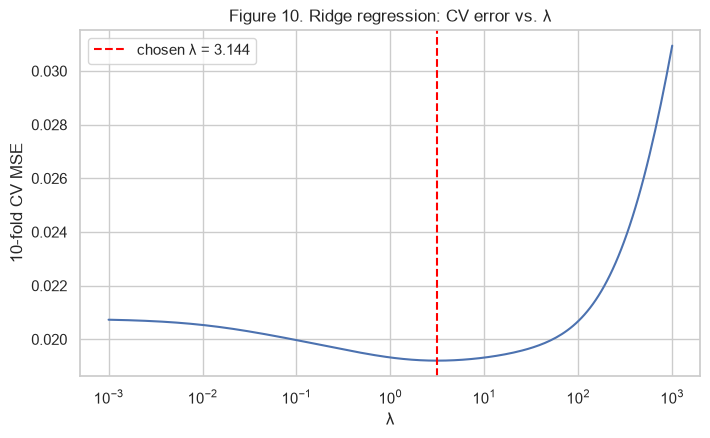

In [26]:
kfold = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

ridge_alphas = np.logspace(-3, 3, 200)
ridge_cv_mse = [-cross_val_score(Ridge(alpha=a), X_train, y_train, cv=kfold,
                                 scoring="neg_mean_squared_error").mean() for a in ridge_alphas]
ridge = RidgeCV(alphas=ridge_alphas, cv=kfold, scoring="neg_mean_squared_error").fit(X_train, y_train)
results["Ridge"] = mean_squared_error(y_test, ridge.predict(X_test))

print(f"ridge: chosen lambda = {ridge.alpha_:.4f}")
print(f"ridge: test MSE      = {results['Ridge']:.5f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(ridge_alphas, ridge_cv_mse)
ax.axvline(ridge.alpha_, color="red", ls="--", label=f"chosen λ = {ridge.alpha_:.3f}")
ax.set(xlabel="λ", ylabel="10-fold CV MSE", title="Figure 10. Ridge regression: CV error vs. λ")
ax.legend()
plt.show()

### 2h. LASSO with λ chosen by cross-validation

First I fit the LASSO on the features as they are. The data are already scaled to the range 0 to 1,
but the features do not have the same spread. The first line of output below shows how much their standard deviations differ.

Then I repeat the fit with standardized features, so every feature has mean 0 and standard deviation 1.
The scaler learns the mean and the standard deviation from the training set only. The test set is scaled with these training values.

In [27]:
train_std = X_train.std()
print(f"standard deviations of the features in the training set: from {train_std.min():.3f} to {train_std.max():.3f}\n")

lasso_alphas = np.logspace(-6, -1, 100)

lasso = LassoCV(alphas=lasso_alphas, cv=kfold, max_iter=100_000).fit(X_train, y_train)
results["LASSO"] = mean_squared_error(y_test, lasso.predict(X_test))
selected = pd.Series(lasso.coef_, index=FEATURE_NAMES)
selected = selected[selected != 0].sort_values(key=np.abs, ascending=False)

print(f"LASSO, normalized features: chosen lambda = {lasso.alpha_:.6f}")
print(f"LASSO, normalized features: test MSE      = {results['LASSO']:.5f}")
print(f"LASSO, normalized features: {len(selected)} of {len(FEATURE_NAMES)} variables selected")

standard deviations of the features in the training set: from 0.054 to 0.446



LASSO, normalized features: chosen lambda = 0.000118
LASSO, normalized features: test MSE      = 0.01763
LASSO, normalized features: 74 of 122 variables selected


In [28]:
lasso_std = make_pipeline(StandardScaler(),
                          LassoCV(alphas=lasso_alphas, cv=kfold, max_iter=100_000)).fit(X_train, y_train)
lasso_std_model = lasso_std[-1]
results["LASSO, standardized"] = mean_squared_error(y_test, lasso_std.predict(X_test))
selected_std = pd.Series(lasso_std_model.coef_, index=FEATURE_NAMES)
selected_std = selected_std[selected_std != 0].sort_values(key=np.abs, ascending=False)

print(f"LASSO, standardized features: chosen lambda = {lasso_std_model.alpha_:.6f}")
print(f"LASSO, standardized features: test MSE      = {results['LASSO, standardized']:.5f}")
print(f"LASSO, standardized features: {len(selected_std)} of {len(FEATURE_NAMES)} variables selected")

LASSO, standardized features: chosen lambda = 0.000673
LASSO, standardized features: test MSE      = 0.01771
LASSO, standardized features: 76 of 122 variables selected


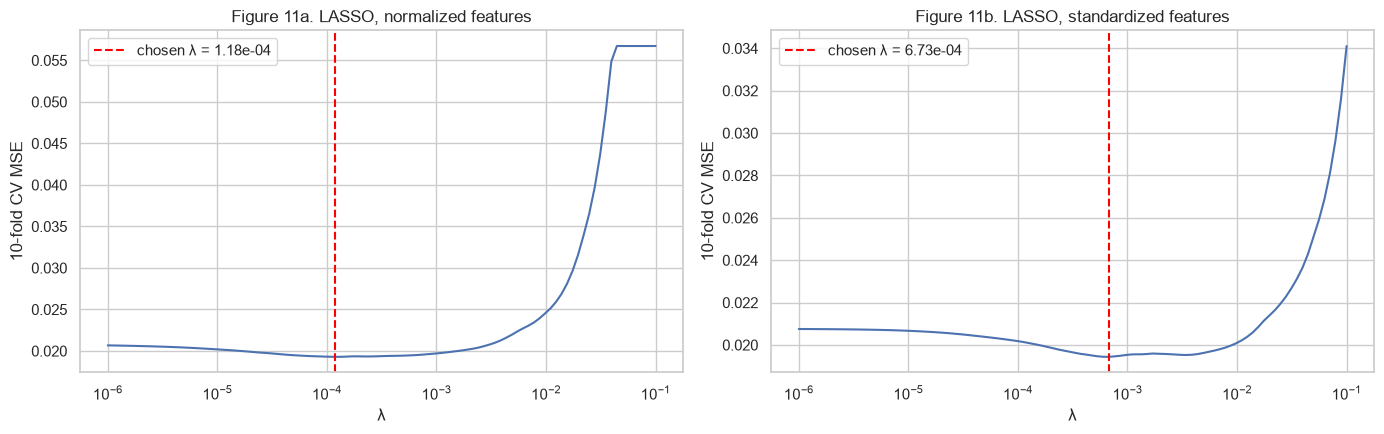

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, model, title in [(axes[0], lasso, "Figure 11a. LASSO, normalized features"),
                         (axes[1], lasso_std_model, "Figure 11b. LASSO, standardized features")]:
    mean_mse = model.mse_path_.mean(axis=1)
    ax.semilogx(model.alphas_, mean_mse)
    ax.axvline(model.alpha_, color="red", ls="--", label=f"chosen λ = {model.alpha_:.2e}")
    ax.set(xlabel="λ", ylabel="10-fold CV MSE", title=title)
    ax.legend()
plt.tight_layout()
plt.show()

#### Variables selected by the LASSO

The table lists every selected variable with its coefficient in both fits. It is sorted by the size of the coefficient in the first fit.
An empty cell means that the fit did not select that variable.
The standardized coefficients are on a different scale, so only their signs and their order can be compared with the first column.

In [30]:
coef_table = pd.DataFrame({"coef, normalized features": selected,
                           "coef, standardized features": selected_std})
coef_table = coef_table.reindex(coef_table["coef, normalized features"].abs()
                                .sort_values(ascending=False, na_position="last").index)
with pd.option_context("display.max_rows", 130):
    display(coef_table.round(4).fillna(""))

both = selected.index.intersection(selected_std.index)
only_normalized = sorted(set(selected.index) - set(selected_std.index))
only_standardized = sorted(set(selected_std.index) - set(selected.index))
print(f"selected in both fits: {len(both)}")
print("only in the normalized fit:  ", ", ".join(only_normalized))
print("only in the standardized fit:", ", ".join(only_standardized))

std_rank = train_std.rank()
print("\nstandard deviation of these variables in the training set:")
for name in only_normalized + only_standardized:
    print(f"    {name}: {train_std[name]:.3f}, number {int(std_rank[name])} of {len(FEATURE_NAMES)} counting from the smallest")

,"coef, normalized features","coef, standardized features"
racepctblack,0.2678,0.0679
agePct12t29,-0.2613,-0.0416
PctPersDenseHous,0.2135,0.0423
PctKids2Par,-0.1983,-0.0407
MedRent,0.1594,0.0289
RentLowQ,-0.1578,-0.0298
NumStreet,0.1574,0.0174
PctPopUnderPov,-0.1398,-0.0285
PctEmploy,0.1368,0.024
MalePctNevMarr,0.1317,0.0234


selected in both fits: 73
only in the normalized fit:   PctBornSameState
only in the standardized fit: LemasTotalReq, OfficAssgnDrugUnits, PctImmigRec5

standard deviation of these variables in the training set:
    PctBornSameState: 0.206, number 82 of 122 counting from the smallest
    LemasTotalReq: 0.072, number 10 of 122 counting from the smallest
    OfficAssgnDrugUnits: 0.054, number 1 of 122 counting from the smallest
    PctImmigRec5: 0.214, number 92 of 122 counting from the smallest


#### Comparison of the two LASSO fits

The two fits have almost the same test MSE, 0.01763 and 0.01771. They also select about the same number of variables, 74 and 76,
and 73 variables are selected by both. Both test errors are a little lower than the test error of least squares, 0.01797.
The LASSO drops about 40% of the variables and shrinks the rest. This lowers the variance of a model that has many collinear features.

Standardizing changes which variables the LASSO keeps, but only a little here.
Without standardizing, the same λ is applied to features with different spreads.
A feature with a small spread needs a large coefficient to have an effect, so it pays a larger penalty and is more likely to be dropped.
Standardizing gives every feature the same spread, so the penalty treats all features the same way.

The results match this idea. Two of the three variables that only the standardized fit selects are `OfficAssgnDrugUnits` and `LemasTotalReq`.
`OfficAssgnDrugUnits` has the smallest standard deviation of all 122 features, and `LemasTotalReq` has the 10th smallest.
Footnote 4 says that the features are already normalized, so the two fits are still close. In general, standardizing is the safer choice for the LASSO.

### 2i. Principal components regression with M chosen by cross-validation

PCR standardizes the features, projects them onto the first $M$ principal components, and fits least squares on those components.
I try every $M$ from 1 to 122 with the same 10 folds.
The scaler and the PCA are inside a pipeline, so they are fit again on the training part of each fold.

In [31]:
pcr = make_pipeline(StandardScaler(), PCA(), LinearRegression())
pcr_search = GridSearchCV(pcr, {"pca__n_components": range(1, len(FEATURE_NAMES) + 1)},
                          cv=kfold, scoring="neg_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
best_m = pcr_search.best_params_["pca__n_components"]
results["PCR"] = mean_squared_error(y_test, pcr_search.predict(X_test))

pcr_cv = pd.DataFrame(pcr_search.cv_results_)
pcr_cv_mse = -pcr_cv["mean_test_score"].to_numpy()
pcr_cv_se = pcr_cv["std_test_score"].to_numpy() / np.sqrt(kfold.get_n_splits())
explained = pcr_search.best_estimator_["pca"].explained_variance_ratio_.sum()

print(f"PCR: chosen M = {best_m}, CV MSE = {pcr_cv_mse.min():.5f}, "
      f"these components explain {explained:.1%} of the feature variance")
print(f"PCR: test MSE = {results['PCR']:.5f}")

m_1se = int(np.argmax(pcr_cv_mse <= pcr_cv_mse.min() + pcr_cv_se[best_m - 1])) + 1
pcr_1se = make_pipeline(StandardScaler(), PCA(n_components=m_1se), LinearRegression()).fit(X_train, y_train)
print(f"For reference, the one-standard-error rule gives M = {m_1se} "
      f"with test MSE = {mean_squared_error(y_test, pcr_1se.predict(X_test)):.5f}")

PCR: chosen M = 95, CV MSE = 0.01985, these components explain 99.8% of the feature variance
PCR: test MSE = 0.01830
For reference, the one-standard-error rule gives M = 10 with test MSE = 0.01807


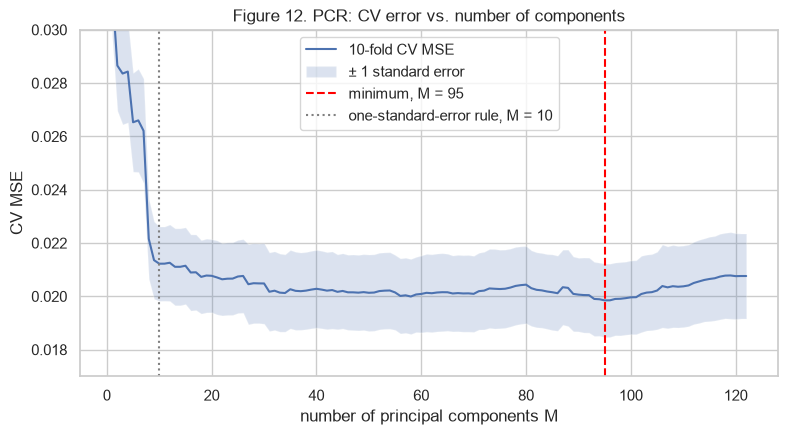

In [32]:
fig, ax = plt.subplots(figsize=(9, 4.5))
m_values = np.arange(1, len(FEATURE_NAMES) + 1)
ax.plot(m_values, pcr_cv_mse, label="10-fold CV MSE")
ax.fill_between(m_values, pcr_cv_mse - pcr_cv_se, pcr_cv_mse + pcr_cv_se, alpha=0.2, label="± 1 standard error")
ax.axvline(best_m, color="red", ls="--", label=f"minimum, M = {best_m}")
ax.axvline(m_1se, color="gray", ls=":", label=f"one-standard-error rule, M = {m_1se}")
ax.set(xlabel="number of principal components M", ylabel="CV MSE", ylim=(0.017, 0.03),
       title="Figure 12. PCR: CV error vs. number of components")
ax.legend()
plt.show()

The CV error falls fast for the first 10 components and then stays almost flat. The minimum is at $M = 95$.
The first components explain most of the spread of the features, but PCA builds them without looking at the target.
So the components that matter most for the target are not always the first ones, and PCR needs many components here.
Its test MSE is a little higher than the test MSE of least squares, ridge and the LASSO.

Because the curve is so flat, the one-standard-error rule picks $M = 10$. This model is much simpler,
and its test MSE is almost the same, 0.01807 compared with 0.01830.
The assignment asks for $M$ chosen by cross-validation, so I report the model with the lowest CV error, $M = 95$.

### 2j. L1-penalized gradient boosting tree with XGBoost

XGBoost builds a model that is a sum of many regression trees. Each new tree is built to reduce the error that the earlier trees left.
The objective adds a penalty for every tree. For a tree with $T$ leaves and leaf weights $w_1, \dots, w_T$, the penalty is

$$\gamma T + \frac{1}{2}\lambda \sum_{j=1}^{T} w_j^2 + \alpha \sum_{j=1}^{T} |w_j|$$

The last term is the L1 penalty, and XGBoost calls $\alpha$ `reg_alpha`.
XGBoost does not fit a full linear regression in each node. Each leaf holds one number, its weight, and the L1 penalty acts on these weights.
It shrinks the weights toward 0 and can set small ones to exactly 0, like the LASSO does with coefficients.
To get a tree with only the L1 penalty, I set the L2 weight `reg_lambda` to 0.

I choose $\alpha$ by 10-fold cross-validation on the training set. I use the same folds as before and try 16 values from $10^{-4}$ to $10^{1.5}$.
The other settings are fixed at common values for a small data set: 500 trees with a depth of 3, a learning rate of 0.03,
and for each tree a random 80% of the rows and 50% of the features.

In [33]:
xgb = XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8,
                   colsample_bytree=0.5, reg_lambda=0.0, objective="reg:squarederror",
                   random_state=RANDOM_STATE, n_jobs=-1)
xgb_alphas = np.logspace(-4, 1.5, 16)
xgb_search = GridSearchCV(xgb, {"reg_alpha": xgb_alphas}, cv=kfold,
                          scoring="neg_mean_squared_error").fit(X_train, y_train)
best_xgb_alpha = xgb_search.best_params_["reg_alpha"]
results["XGBoost with L1 penalty"] = mean_squared_error(y_test, xgb_search.predict(X_test))

xgb_cv = pd.DataFrame(xgb_search.cv_results_)
xgb_cv_mse = -xgb_cv["mean_test_score"].to_numpy()
print(f"XGBoost: chosen alpha = {best_xgb_alpha:.4f}, CV MSE = {xgb_cv_mse.min():.5f}")
print(f"XGBoost: test MSE     = {results['XGBoost with L1 penalty']:.5f}")
display(pd.DataFrame({"reg_alpha": xgb_alphas, "CV MSE": xgb_cv_mse}).round(5).T)

XGBoost: chosen alpha = 0.4642, CV MSE = 0.01936
XGBoost: test MSE     = 0.01573


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
reg_alpha,0.00010,0.00023,0.00054,0.00126,0.00293,0.00681,0.01585,0.03687,0.08577,0.19953,0.46416,1.07978,2.51189,5.84341,13.59356,31.62278
CV MSE,0.01957,0.01964,0.01959,0.01958,0.01960,0.01957,0.01959,0.01953,0.01944,0.01937,0.01936,0.01955,0.01980,0.02033,0.02231,0.02898


5 most important features: PctIlleg, PctKids2Par, PctFam2Par, NumIlleg, racePctWhite


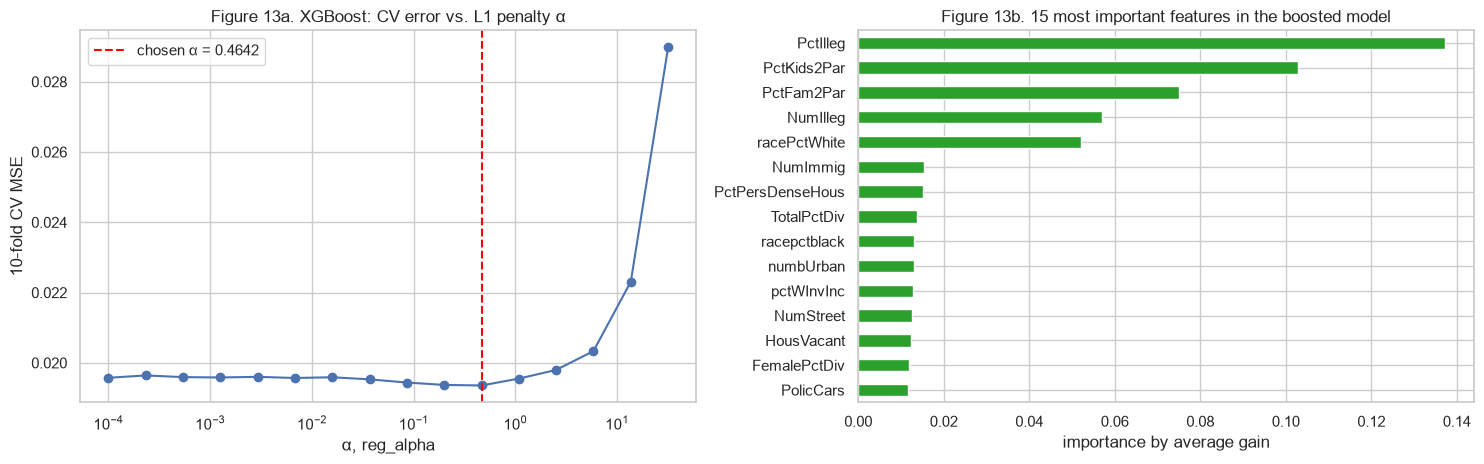

In [34]:
importance = pd.Series(xgb_search.best_estimator_.feature_importances_, index=FEATURE_NAMES)
print("5 most important features:", ", ".join(importance.sort_values(ascending=False).index[:5]))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].semilogx(xgb_alphas, xgb_cv_mse, marker="o")
axes[0].axvline(best_xgb_alpha, color="red", ls="--", label=f"chosen α = {best_xgb_alpha:.4f}")
axes[0].set(xlabel="α, reg_alpha", ylabel="10-fold CV MSE",
            title="Figure 13a. XGBoost: CV error vs. L1 penalty α")
axes[0].legend()

importance.sort_values().tail(15).plot.barh(ax=axes[1], color="tab:green")
axes[1].set(xlabel="importance by average gain", title="Figure 13b. 15 most important features in the boosted model")
plt.tight_layout()
plt.show()

The CV error is almost flat for $\alpha$ below 1, with a small dip and the minimum at $\alpha \approx 0.46$.
For larger $\alpha$, the penalty shrinks the leaf weights too much, and the CV error rises fast.

Four of the five most important features in the boosted model are `PctIlleg`, `PctKids2Par`, `PctFam2Par` and `racePctWhite`.
These are also the four features with the strongest correlation with the target in 2c.